# Treasure Hunt Game Notebook

## Read and Review Your Starter Code
The theme of this project is a popular treasure hunt game in which the player needs to find the treasure before the pirate does. While you will not be developing the entire game, you will write the part of the game that represents the intelligent agent, which is a pirate in this case. The pirate will try to find the optimal path to the treasure using deep Q-learning. 

<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>TreasureHuntGame_starterCode.ipynb</b> file to complete your assignment. 
<br><br>
You have been provided with two Python classes and this notebook to help you with this assignment. The first class, <b>TreasureMaze.py</b>, represents the environment, which includes a maze object defined as a matrix. The second class, <b>GameExperience.py</b>, stores the episodes – that is, all the states that come in between the initial state and the terminal state. This is later used by the agent for learning by experience, called "exploration". This notebook shows how to play a game. Your task is to complete the deep Q-learning implementation in the qtrain() function for which a skeleton implementation has been provided. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
<b>NOTE: </b>The code block you will need to complete will have <b>#TODO</b> as a header.
<br> First, read and review the next few code and instruction blocks to understand the code that you have been given.</div>

<div class="alert alert-block alert-warning" style="color: #333333;">
<b>Installations</b> The following command will install the necessary Python libraries to necessary to run this application. If you see a "[notice] A new release of pip is available: 23.1.2 -> 25.2" at the end of the installation, you may disregard that statement. 
</div>

In [1]:
!pip install -r requirements.txt


[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


<h2>Tensorflow CPU Acceleration Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
    <b>Example messages:</b>
    <ul>
        <li>oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders</li>
        <li>WARNING: All log messages before absl::InitializeLog() is called are written to STDERR</li>
</div>

In [2]:
from __future__ import print_function
import os, sys, time, datetime, json, random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import clone_model
from keras.models import Sequential
from keras.layers import Dense, Activation, PReLU
from keras.optimizers import SGD , Adam, RMSprop
import matplotlib.pyplot as plt
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience
%matplotlib inline

<h2> Maze Object Generation</h2>

<div class="alert alert-block alert-info" style="color:black;">
    <b>NOTE:</b>  The following code block contains an 8x8 matrix that will be used as a maze object:
</div>

In [3]:
maze = np.array([
    [ 1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  0.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  0.,  0.,  0.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  1.,  1.]
])

<h2>Helper Functions and Global Variables</h2>

<div class="alert alert-block alert-info" style="color:black;">
This <b>show()</b> helper function allows a visual representation of the maze object:
</div>

In [4]:
def show(qmaze):
    plt.grid('on')
    nrows, ncols = qmaze.maze.shape
    ax = plt.gca()
    ax.set_xticks(np.arange(0.5, nrows, 1))
    ax.set_yticks(np.arange(0.5, ncols, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    canvas = np.copy(qmaze.maze)
    for row,col in qmaze.visited:
        canvas[row,col] = 0.6
    pirate_row, pirate_col, _ = qmaze.state
    canvas[pirate_row, pirate_col] = 0.3   # pirate cell
    canvas[nrows-1, ncols-1] = 0.9 # treasure cell
    img = plt.imshow(canvas, interpolation='none', cmap='gray')
    return img

The <b>pirate agent</b> can move in four directions: left, right, up, and down. 

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note:</b> While the agent primarily learns by experience through exploitation, often, the agent can choose to explore the environment to find previously undiscovered paths. This is called "exploration" and is defined by epsilon. This value is the <b>EXPLORATION</b> values from the Cartpole assignment. The hyperparameters are provided here and used in the <b>qtrain()</b> method. 
You are encouraged to try various values for the exploration factor and see how the algorithm performs.
</div>

In [5]:
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3


# Exploration factor
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10

# Actions dictionary
actions_dict = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down',
}

num_actions = len(actions_dict)


The sample code block and output below show creating a maze object and performing one action (DOWN), which returns the reward. The resulting updated environment is visualized.

reward= -0.04


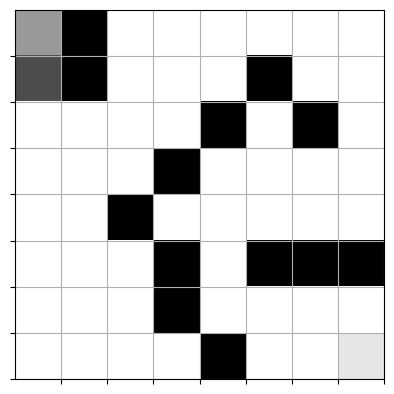

In [6]:
qmaze = TreasureMaze(maze)
canvas, reward, game_over = qmaze.act(DOWN)
print("reward=", reward)
show(qmaze)

<div class="alert alert-block alert-warning" style="color:black;">
    <b>NOTE:</b> This <b>play_game()</b> function simulates a full game based on the provided trained model. The other parameters include the TreasureMaze object, the starting position of the pirate and max amount of steps to make sure the code does not get stuck in a loop.
</div>

In [7]:
def play_game(model, qmaze, pirate_cell, max_steps=None):
    qmaze.reset(pirate_cell)
    envstate = qmaze.observe()
    steps = 0

    if max_steps is None:
        max_steps = qmaze.maze.size * 4  # safety cutoff

    while steps < max_steps:

        # Convert the current environment state into
        # the format expected by the neural network.
        state = np.asarray(envstate, dtype=np.float32)

        if state.ndim == 1:
            state = np.expand_dims(state, axis=0)

        # Get the Q-values predicted by the trained model.
        q_values = model(state, training=False).numpy()[0]

        # Only allow actions that are legal from the
        # pirate's current position.
        valid_actions = qmaze.valid_actions()

        if not valid_actions:
            return False

        # Choose the valid action with the highest Q-value.
        action = max(
            valid_actions,
            key=lambda a: q_values[a]
        )

        # Perform the selected action.
        envstate, reward, game_status = qmaze.act(action)

        steps += 1

        # The pirate successfully reached the treasure.
        if game_status == 'win':
            return True

        # The game ended unsuccessfully.
        elif game_status == 'lose':
            return False

    # The pirate did not reach the treasure within
    # the maximum allowed number of steps.
    return False

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
    This <b>completion_check()</b> function helps you to determine whether the pirate can win any game at all. If your maze is not well designed, the pirate may not win any game at all. In this case, your training would not yield any result. The provided maze in this notebook ensures that there is a path to win and you can run this method to check.
</div>

In [8]:
def completion_check(model, maze_or_qmaze, max_steps=None):
    # Accept either raw numpy maze or TreasureMaze instance
    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:
        if not qmaze.valid_actions(cell):
            continue
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
</b>The <b>build_model()</b> function in the block below will build the neural network model. Review the code and note the number of layers, as well as the activation, optimizer, and loss functions that are used to train the model.
</div>

In [9]:
def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model

<div class="alert alert-block alert-warning" style="color:black;">
    <b>Note:</b>
    This <b>train_step()</b> helper function in the block below is used to help predict Q-values (quality values) in the current modelto see how good each action is in a given state and improve the Q-network by reducing the gap between what is predicted and what should have been predicted. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
If you're interested in reading up on the <i>@tf.function</i>, which is a decorator for Tensorflow to run this code into a TensorFlow computation graph, please refer to this link: <a href="https://www.tensorflow.org/guide/intro_to_graphs">https://www.tensorflow.org/guide/intro_to_graphs</a>
</div>


<h2>Tensorflow GPU Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
    You will see a <b>warning in red</b> "INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.". This is simply coming from <b>Tensorflow skipping using GPU for this assignment.</b>  
</div>

In [10]:
loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.Adam()

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        q_values = model(x, training=True)
        loss = loss_fn(y, q_values)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

I0000 00:00:1786909315.536990     459 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1786909315.588749     459 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1786909315.590383     459 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1786909315.593216     459 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

In [11]:
def format_time(seconds):
    if seconds < 400:
        return "%.1f seconds" % seconds
    elif seconds < 4000:
        return "%.2f minutes" % (seconds / 60.0)
    else:
        return "%.2f hours" % (seconds / 3600.0)

# #TODO: Complete the Q-Training Algorithm Code Block

<div class="alert alert-block alert-info" style="color:black;">
    This is your deep Q-learning implementation. The goal of your deep Q-learning implementation is to find the best possible navigation sequence that results in reaching the treasure cell while maximizing the reward. In your implementation, you need to determine the optimal number of epochs to achieve a 100% win rate.
</div>
    <b>Pseudocode:</b>
    <br>
    For each epoch:
        Reset the environment at a random starting cell
        agent_cell = randomly select a free cell
        <br>
        <b>Hint:</b> Review the reset method in the TreasureMaze.py class.
    
        Set the initial environment state
        env_state should reference the environment's current state
        Hint: Review the observe method in the TreasureMaze.py class.

        While game status is not game over:
           previous_envstate = env_state
            Decide on an action:
                - If possible, take a random valid exploration action and 
                  randomly choose action (left, right, up, down)
                  and assign it to an action variable
                - Else, pick the best exploitation action from the model and assign it to an action variable
                  Hint: Review the predict method in the GameExperience.py class.
    
           Retrieve the values below from the act() method.
           env_state, reward, game_status = qmaze.act(action)
           Hint: Review the act method in the TreasureMaze.py class.
    
            Track the wins and losses from the game_status using win_history 
         
           Store the episode below in the Experience replay object
           episode = [previous_envstate, action, reward, envstate, game_status]
           Hint: Review the remember method in the GameExperience.py class.
        
           Train neural network model and evaluate loss
           Hint: Call GameExperience.get_data to retrieve training data (input and target) 
           and pass to the train_step method and assign it to batch_loss and append to the loss variable
        
      If the win rate is above the threshold and your model passes the completion check, that would be your epoch.

Note: A 100% win rate <b>DOES NOT EXPLICITLY MEAN</b> that you have solved the maze. It simply indicates that during the last evaluation, the pirate <i>happened</i> to get to the treasure. Be sure to utilise the <b>completion_check()</b> function to validate your pirate found the treasure at every starting point and consistently! 

<b> You will need to complete the section starting with #START_HERE. Please use the pseudocode above as guidance. </b>


In [12]:
def qtrain(model, maze, **opt):
    global epsilon

    n_epoch = opt.get("n_epoch", 15000)
    max_memory = opt.get("max_memory", 1000)
    data_size = opt.get("data_size", 50)
    target_update_freq = opt.get("target_update_freq", 50)

    start_time = datetime.datetime.now()

    # Create the maze environment
    qmaze = TreasureMaze(maze)

    # Create a target network for more stable Q-learning
    target_model = clone_model(model)
    target_model.set_weights(model.get_weights())

    # Experience replay stores previous game experiences
    experience = GameExperience(
        model,
        target_model,
        max_memory=max_memory
    )

    win_history = []
    hsize = qmaze.maze.size // 2

    win_rate = 0.0
    n_episodes = 0
    loss = 0.0

    for epoch in range(n_epoch):

        # Randomly select a valid starting position
        agent_cell = random.choice(qmaze.free_cells)

        # Reset the maze
        qmaze.reset(agent_cell)
        env_state = qmaze.observe()

        game_status = "not_over"
        epoch_loss = 0.0
        batch_count = 0

        # Continue playing until the game ends
        while game_status == "not_over":

            previous_envstate = env_state

            # Get actions that are valid from the current position
            valid_actions = qmaze.valid_actions()

            if not valid_actions:
                game_status = "lose"
                win_history.append(0)
                break

            # Exploration versus exploitation
            if np.random.rand() < epsilon:

                # Exploration: randomly choose a valid action
                action = random.choice(valid_actions)

            else:

                # Exploitation: choose the action with the
                # highest predicted Q-value
                q_values = np.asarray(
                    experience.predict(previous_envstate)
                ).reshape(-1)

                action = max(
                    valid_actions,
                    key=lambda a: q_values[a]
                )

            # Perform the selected action
            env_state, reward, game_status = qmaze.act(action)

            # Store the experience
            episode = [
                previous_envstate,
                action,
                reward,
                env_state,
                game_status
            ]

            experience.remember(episode)

            # Retrieve training data from experience replay
            inputs, targets = experience.get_data(data_size)

            # Train the neural network
            batch_loss = train_step(inputs, targets)

            if hasattr(batch_loss, "numpy"):
                batch_loss = batch_loss.numpy()

            batch_loss = float(batch_loss)

            epoch_loss += batch_loss
            batch_count += 1
            n_episodes += 1

            # Periodically update the target network
            if n_episodes % target_update_freq == 0:
                target_model.set_weights(model.get_weights())

            # Record the result of the episode
            if game_status == "win":
                win_history.append(1)

            elif game_status == "lose":
                win_history.append(0)

        # Calculate average loss for this epoch
        if batch_count > 0:
            loss = epoch_loss / batch_count
        else:
            loss = 0.0

        # Calculate the recent win rate
        if len(win_history) >= hsize:
            win_rate = sum(win_history[-hsize:]) / hsize
        else:
            win_rate = 0.0

        # Gradually reduce exploration as the agent learns
        if win_rate >= 0.90:
            epsilon = epsilon_min
        else:
            epsilon = max(
                epsilon * epsilon_decay,
                epsilon_min
            )

        # Display training progress
        dt = datetime.datetime.now() - start_time
        t = format_time(dt.total_seconds())

        print(
            "Epoch: {:03d}/{:d} | Loss: {:.4f} | Episodes: {:d} | "
            "Win count: {:d} | Win rate: {:.3f} | epsilon: {:.3f} | time: {}".format(
                epoch,
                n_epoch - 1,
                loss,
                n_episodes,
                sum(win_history),
                win_rate,
                epsilon,
                t
            )
        )

        # Only perform the final completion check after
        # enough episodes have been completed.
        if len(win_history) >= hsize and win_rate >= 0.999:

            if completion_check(model, maze):

                print(
                    "Verified 100% completion at epoch {}".format(epoch)
                )

                break

    # Synchronize the target network with the final model
    target_model.set_weights(model.get_weights())

    total_time = format_time(
        (datetime.datetime.now() - start_time).total_seconds()
    )

    print("Training complete in:", total_time)

## Test Your Model

Now we will start testing the deep Q-learning implementation. To begin, select **Cell**, then **Run All** from the menu bar. This will run your notebook. As it runs, you should see output begin to appear beneath the next few cells. The code below creates an <b>instance</b> of TreasureMaze. This does not show your actual training done.

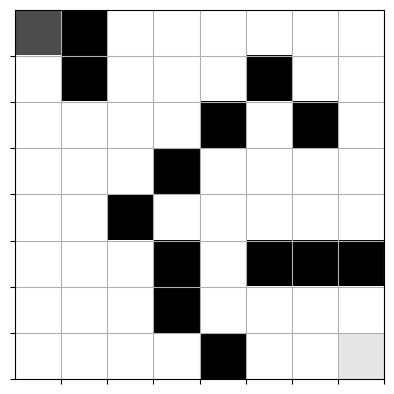

In [13]:
qmaze = TreasureMaze(maze)
show(qmaze)

In the next code block, you will build your model using the <b>build_model</b> function and train it using deep Q-learning. Note: This step takes several minutes to fully run.



<div class="alert alert-block alert-danger" style="color: #333333;">
  <b>WARNING</b>  If you did not attempt the assignment, the code <b>will</b> error out at this section.
 </div>

In [14]:
model = build_model(maze)

/home/codio/.pyenv/versions/3.11.9/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
epsilon = 1.0

qtrain(
    model,
    maze,
    n_epoch=3000,
    max_memory=16 * maze.size,
    data_size=64,
    target_update_freq=50
)

Epoch: 000/2999 | Loss: 0.0074 | Episodes: 100 | Win count: 1 | Win rate: 0.000 | epsilon: 0.995 | time: 3.1 seconds
Epoch: 001/2999 | Loss: 0.0041 | Episodes: 133 | Win count: 2 | Win rate: 0.000 | epsilon: 0.990 | time: 3.6 seconds
Epoch: 002/2999 | Loss: 0.0053 | Episodes: 281 | Win count: 2 | Win rate: 0.000 | epsilon: 0.985 | time: 5.6 seconds
Epoch: 003/2999 | Loss: 0.0037 | Episodes: 431 | Win count: 2 | Win rate: 0.000 | epsilon: 0.980 | time: 7.8 seconds
Epoch: 004/2999 | Loss: 0.0029 | Episodes: 580 | Win count: 2 | Win rate: 0.000 | epsilon: 0.975 | time: 10.0 seconds
Epoch: 005/2999 | Loss: 0.0026 | Episodes: 728 | Win count: 2 | Win rate: 0.000 | epsilon: 0.970 | time: 12.1 seconds
Epoch: 006/2999 | Loss: 0.0026 | Episodes: 887 | Win count: 2 | Win rate: 0.000 | epsilon: 0.966 | time: 14.3 seconds
Epoch: 007/2999 | Loss: 0.0026 | Episodes: 1042 | Win count: 2 | Win rate: 0.000 | epsilon: 0.961 | time: 16.5 seconds
Epoch: 008/2999 | Loss: 0.0022 | Episodes: 1185 | Win count

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b> This cell will check to see if the model passes the completion check. Note: This could take several minutes.
</div>

Completion check: True


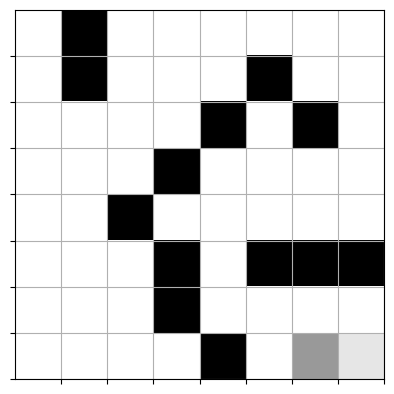

In [16]:
passed = completion_check(model, qmaze)
print("Completion check:", passed)
show(qmaze)

This cell will test your model for one game. It will start the pirate at the top-left corner and run <b>play_game()</b>. The agent should find a path from the starting position to the target (treasure). The treasure is located in the bottom-right corner.

Pirate reached treasure: True


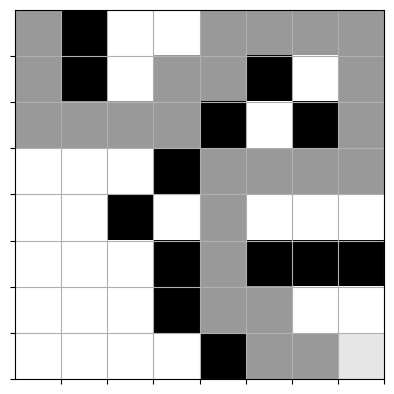

In [17]:
pirate_start = (0, 0)
won = play_game(model, qmaze, pirate_start)
print("Pirate reached treasure:", won)
show(qmaze)

## Save and Submit Your Work

<div class="alert alert-block alert-info" style="color:black;">
    <b># Project Two Design Defense

## Introduction

The purpose of this project was to develop an intelligent pirate agent that could navigate a maze and reach a treasure location using deep Q-learning. Instead of programming a specific path for the pirate to follow, the agent learns through repeated interaction with the maze. The pirate receives rewards based on its actions and uses those experiences to improve its future decisions.

The project uses the `TreasureMaze` environment and the `GameExperience` class to store experiences from previous games. The pirate can move in four directions: left, right, up, and down. The goal is for the pirate to learn an effective path to the treasure while improving its performance through training.

## Human Versus Machine Maze Solving

A human and a machine approach a maze differently. A human can use visual information, memory, reasoning, and previous knowledge to decide which direction to move. A person can recognize patterns and change strategies when a path does not work.

The pirate agent does not initially know which path leads to the treasure. Instead, it learns by interacting with the environment. Each action creates a new experience that includes the previous state, the action taken, the reward received, the new state, and the game status. These experiences are stored and later used to train the neural network.

One advantage of the machine approach is that the pirate can repeatedly practice the same problem and improve its decisions based on previous experiences. The trained model can use the information it has learned to select the action with the highest predicted value. This allows the pirate to develop a strategy without being given a specific solution in advance.

## Exploration and Exploitation

Exploration and exploitation are important parts of reinforcement learning. Exploration occurs when the pirate tries different actions to discover new paths. Exploitation occurs when the pirate uses information it has already learned to select the action that appears to have the highest reward.

If the pirate only exploited its current knowledge, it could repeatedly use a path that appears successful without discovering a better option. Exploration gives the agent opportunities to find new and potentially more effective paths.

The project uses an epsilon value to control exploration. At the beginning of training, epsilon is higher, allowing the pirate to explore the maze more frequently. As training continues, epsilon decreases, causing the pirate to rely more heavily on the information learned by the neural network.

This balance is important because the pirate needs to discover useful paths before it can consistently exploit them. Early exploration provides experiences for the neural network, while later exploitation allows the agent to use those experiences to make better decisions.

## Neural Network and Deep Q-Learning

The intelligent agent uses deep Q-learning to determine which actions are most valuable. The neural network receives the current state of the maze and produces values representing the expected value of the available actions. The pirate can then select the valid action with the highest predicted value.

The project also uses experience replay. Instead of training only on the most recent action, the agent stores previous experiences and uses samples from those experiences during training. This gives the neural network access to a larger variety of situations and helps the model learn from previous games.

The training configuration allows up to 3,000 epochs. The replay memory is based on 16 times the size of the maze, the training data size is 64, and the target network is updated every 50 epochs. These settings provide the model with enough opportunities to learn from its experiences while helping keep the training process stable.

The target network is useful because it provides more stable values for the learning process. The primary model continues learning while the target model is periodically updated. This helps prevent the values used during training from changing too rapidly.

## Evaluation of the Intelligent Agent

The pirate's performance cannot be evaluated only by looking at whether it wins one game. A single successful game does not necessarily mean that the agent has learned a reliable solution. The project includes a `completion_check()` function to verify that the pirate can consistently reach the treasure.

The training output records several important measurements, including loss, number of episodes, win count, win rate, epsilon, and training time. These values help show how the model changes during training.

Win rate is useful for measuring how frequently the pirate reaches the treasure. Loss provides information about the neural network's training performance, while epsilon shows how the balance between exploration and exploitation changes during training.

The completion check provides a stronger evaluation because it tests whether the pirate can successfully navigate the maze rather than simply getting lucky during one game. A successful model should consistently reach the treasure from the valid starting positions.

## Conclusion

This project demonstrates how deep reinforcement learning can be used to create an intelligent agent that learns through experience. The pirate is not given a predetermined solution. Instead, it interacts with the maze, receives rewards, stores its experiences, and uses a neural network to improve its decisions.

The balance between exploration and exploitation is especially important. Exploration allows the pirate to discover new paths, while exploitation allows it to use the knowledge it has already gained. As training continues, the pirate becomes more dependent on its learned strategy.

Deep Q-learning, experience replay, and the target network work together to help the pirate learn a reliable navigation strategy. The completion check then provides a way to verify that the trained model can consistently reach the treasure. Overall, the project demonstrates how reinforcement learning and neural networks can be combined to solve a navigation problem through learning rather than hard-coded instructions.

## References

Mnih, V., Kavukcuoglu, K., Silver, D., Rusu, A. A., Veness, J., Bellemare, M. G., Graves, A., Riedmiller, M., Fidjeland, A. K., Ostrovski, G., Petersen, S., Beattie, C., Sadik, A., Antonoglou, I., King, H., Kumaran, D., Wierstra, D., Legg, S., & Hassabis, D. (2015). Human-level control through deep reinforcement learning. *Nature, 518*(7540), 529–533. https://doi.org/10.1038/nature14236

Sutton, R. S., & Barto, A. G. (2018). *Reinforcement learning: An introduction* (2nd ed.). The MIT Press.
</div>

After you have finished creating the code for your notebook, save your work.
Make sure that your notebook contains your name in the filename (e.g. Doe_Jane_ProjectTwo.html). Download this file as an .html file clicking on ***file*** in *Jupyter Notebook*, navigating down to ***Download as*** and clicking on ***.html***. 
Download a copy of your .html file and submit it to Brightspace.